# Thesis Fig. 9 — parameter sweeps of the online kernel-learning system

Reproduction of Tepper (2026), Fig. 9 (thesis PDF p. 114; printed p. 107), panel by panel.

> Top: readout–target error over kernel epochs while varying N, K0 and λ. Bottom: converged total error over paired
> sweeps (N × λ, K0 × N, λ × K0); the numbers in the last heatmap are the optimal sampling rates T*.

**Panels:** A learning vs N · B learning vs K0 · C learning vs λ · D converged error N × λ · E converged error K0 × N ·
F converged error λ × K0 with T*.

**Acceptance (spec 6A.6):** error falls with N and K0 and rises with λ; T* values reported (and compared with the
36 printed values).

**Parameters [D11]:** `configs/thesis/fig9.yaml`. The narrowband target (ξ0 = 24, ℓ = 3) was identified by matching
the printed T* grid; λ and K0 are in the thesis's unitary units (×N in D10 units). Learning uses eq. 9.10 as written
on the in-band part of the target (|m| < N/2); errors are the eq. 6.21 terms of the full target, relative to its
energy, so modes beyond N/2 count as network floor. The converged heatmaps use the eq. 7.13 fixed point, which the
learning runs approach (checked below).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seqnet.thesis as th
from seqnet.thesis.figures import load_config, save_data, load_data, save_figure, record_checks, style

style()
FIG = "fig9"
cfg = load_config(FIG)
tg, Mx = cfg["target"], cfg["M_max"]
S_full = th.TargetClass.narrowband(Mx, xi0=tg["xi0"], ell=tg["ell"]).psd

def E_y(N):
    return float(np.sum(th.mode_multiplicity(N, S_full.size) * S_full))

def setup(N, lam_u, K0_u):
    lam, K0 = N * lam_u, N * K0_u
    S_in = S_full[: N // 2 + 1].copy(); S_in[N // 2] = 0.0   # in-band target (Nyquist dropped)
    return lam, K0, S_in

def fixed_point_error(N, lam_u, K0_u):
    lam, K0, S_in = setup(N, lam_u, K0_u)
    wf = th.water_fill(S_in, lam, K0, N=N)
    et = th.error_terms(wf.a, S_full, lam, N, N)
    return et.total / E_y(N), 2 * wf.M_star

def learn(N, lam_u, K0_u, n_steps):
    lam, K0, S_in = setup(N, lam_u, K0_u)
    mult = th.mode_multiplicity(N)
    ik = cfg["initial_kernel"]
    a0 = th.Kernel.from_family(ik["family"], N, sigma=ik["sigma"]).alloc(); a0 *= K0 / np.sum(mult * a0)
    rule = th.ThesisKernelRule(eta=cfg["eta_k_factor"] * lam**2 / (3 * S_in.max()), decay=lam, N=N, K0=K0,
                               budget=cfg["budget"])
    ls = th.LearningSystem(N=N, decay=lam, K0=K0, target=th.TargetClass(psd=S_in), a0=a0, rule=rule,
                           readout=cfg["readout"], seed=cfg["seed"])
    h = ls.run(n_steps).as_arrays()
    err = np.array([th.error_terms(a, S_full, lam, N, N).total for a in h["alloc"]]) / E_y(N)
    return err

D = cfg["defaults"]; n_ep = cfg["kernel_epochs"]

## Panel A — learning with varying N (λ = 0.1, K0 = 10)

In [2]:
Ns = np.array(cfg["sweep_N"])
curves = np.stack([learn(int(n), D["decay"], D["K0"], n_ep) for n in Ns])
fp = np.array([fixed_point_error(int(n), D["decay"], D["K0"])[0] for n in Ns])
save_data(FIG, "A_vary_N", params={"sweep_N": Ns, **D}, values=Ns, curves=curves, fixed_point=fp)

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig9/A_vary_N.npz')

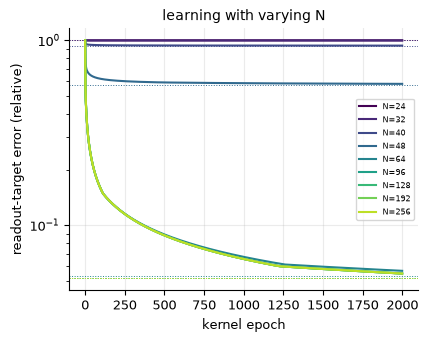

In [3]:
def plot_curves(panel, label, fmt):
    d = load_data(FIG, panel)
    fig, ax = plt.subplots(figsize=(4.5, 3.4))
    cols = plt.cm.viridis(np.linspace(0, 0.9, len(d["values"])))
    for v, c, f, col in zip(d["values"], d["curves"], d["fixed_point"], cols):
        ax.semilogy(c, color=col, label=fmt(v)); ax.axhline(f, ls=":", color=col, lw=0.7)
    ax.set_xlabel("kernel epoch"); ax.set_ylabel("readout-target error (relative)"); ax.legend(fontsize=6); ax.set_title(label)
    save_figure(FIG, panel, fig); plt.show()

plot_curves("A_vary_N", "learning with varying N", lambda v: f"N={int(v)}")

## Panel B — learning with varying K0 (N = 128, λ = 0.1)

In [4]:
K0s = np.array(cfg["sweep_K0"], dtype=float)
curves = np.stack([learn(D["N"], D["decay"], k, n_ep) for k in K0s])
fpT = [fixed_point_error(D["N"], D["decay"], k) for k in K0s]
save_data(FIG, "B_vary_K0", params={"sweep_K0": K0s, **D}, values=K0s, curves=curves,
          fixed_point=np.array([f for f, _ in fpT]), T_star=np.array([t for _, t in fpT]))

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig9/B_vary_K0.npz')

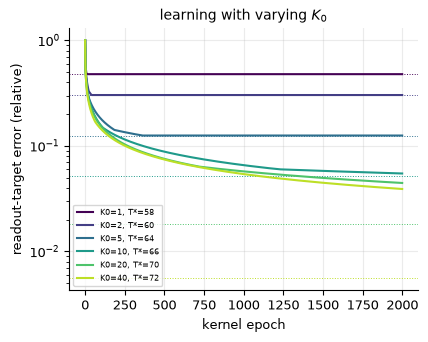

In [5]:
d = load_data(FIG, "B_vary_K0")
plot_curves("B_vary_K0", "learning with varying $K_0$", lambda v: f"K0={v:g}, T*={int(d['T_star'][list(d['values']).index(v)])}")

## Panel C — learning with varying λ (N = 128, K0 = 10)

In [6]:
lams = np.array(cfg["sweep_decay"])
curves = np.stack([learn(D["N"], l, D["K0"], n_ep) for l in lams])
fp = np.array([fixed_point_error(D["N"], l, D["K0"])[0] for l in lams])
save_data(FIG, "C_vary_lambda", params={"sweep_decay": lams, **D}, values=lams, curves=curves, fixed_point=fp)

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig9/C_vary_lambda.npz')

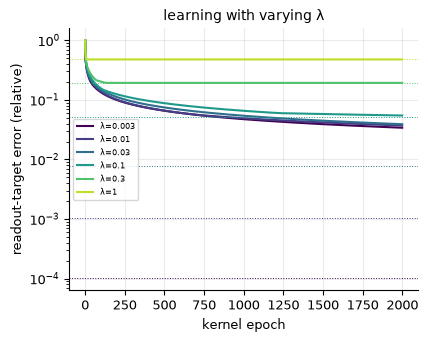

In [7]:
plot_curves("C_vary_lambda", "learning with varying λ", lambda v: f"λ={v:g}")

## Panels D–F — converged total error (eq. 7.13 fixed point) over paired sweeps

In [8]:
def grid(xs, ys, f):
    E = np.zeros((len(ys), len(xs))); T = np.zeros_like(E, dtype=int)
    for i, yv in enumerate(ys):
        for j, xv in enumerate(xs):
            E[i, j], T[i, j] = f(xv, yv)
    return E, T

E_D, T_D = grid(Ns, lams, lambda n, l: fixed_point_error(int(n), l, D["K0"]))
save_data(FIG, "D_N_lambda", x=Ns, y=lams, E=E_D, T=T_D)
E_E, T_E = grid(K0s, Ns, lambda k, n: fixed_point_error(int(n), D["decay"], k))
save_data(FIG, "E_K0_N", x=K0s, y=Ns, E=E_E, T=T_E)
E_F, T_F = grid(lams, K0s, lambda l, k: fixed_point_error(D["N"], l, k))
fig_T = np.array([cfg["figure_T_grid"][int(k)] for k in K0s])
save_data(FIG, "F_lambda_K0", x=lams, y=K0s, E=E_F, T=T_F, figure_T=fig_T)

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig9/F_lambda_K0.npz')

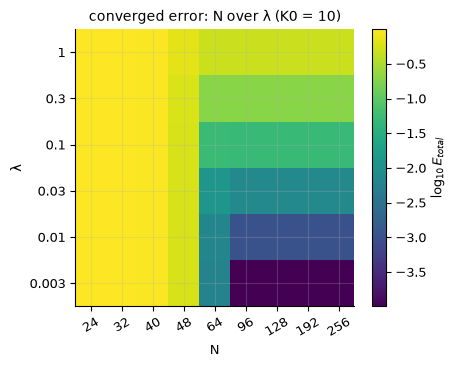

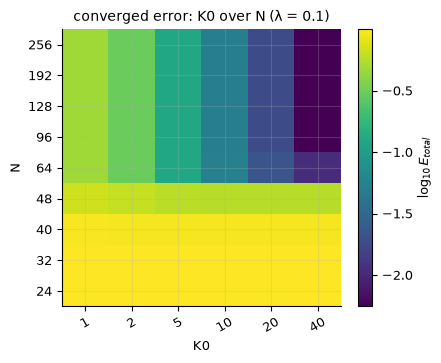

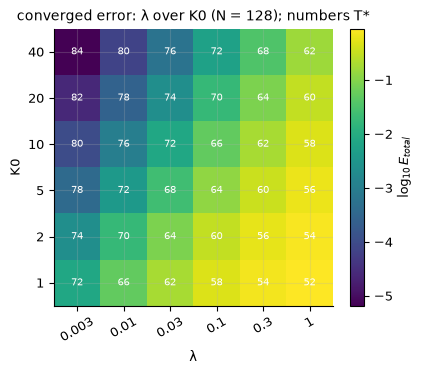

T* reproduced:
 [[72 66 62 58 54 52]
 [74 70 64 60 56 54]
 [78 72 68 64 60 56]
 [80 76 72 66 62 58]
 [82 78 74 70 64 60]
 [84 80 76 72 68 62]] 
T* figure:
 [[72 66 62 58 54 52]
 [74 70 64 60 56 54]
 [78 72 68 64 60 56]
 [80 76 72 66 62 58]
 [82 78 74 70 64 60]
 [84 80 76 72 68 62]]


In [9]:
def heat(panel, xl, yl, title, annotate=False):
    d = load_data(FIG, panel)
    fig, ax = plt.subplots(figsize=(4.5, 3.6))
    im = ax.imshow(np.log10(d["E"]), origin="lower", aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(d["x"])), [f"{v:g}" for v in d["x"]], rotation=30); ax.set_yticks(range(len(d["y"])), [f"{v:g}" for v in d["y"]])
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(title); fig.colorbar(im, ax=ax, label=r"$\log_{10} E_{total}$")
    if annotate:
        for i in range(d["T"].shape[0]):
            for j in range(d["T"].shape[1]):
                ax.text(j, i, f"{d['T'][i, j]}", ha="center", va="center", fontsize=7, color="w")
    save_figure(FIG, panel, fig); plt.show()

heat("D_N_lambda", "N", "λ", "converged error: N over λ (K0 = 10)")
heat("E_K0_N", "K0", "N", "converged error: K0 over N (λ = 0.1)")
heat("F_lambda_K0", "λ", "K0", "converged error: λ over K0 (N = 128); numbers T*", annotate=True)
d = load_data(FIG, "F_lambda_K0"); print("T* reproduced:\n", d["T"], "\nT* figure:\n", d["figure_T"])

## Acceptance

In [10]:
a, b, c = load_data(FIG, "A_vary_N"), load_data(FIG, "B_vary_K0"), load_data(FIG, "C_vary_lambda")
f = load_data(FIG, "F_lambda_K0")
fa, fb, fc = a["fixed_point"], b["fixed_point"], c["fixed_point"]
conv = {k: float(np.max(np.abs(d_["curves"][:, -1] - d_["fixed_point"]) / d_["fixed_point"])) for k, d_ in [("N", a), ("K0", b), ("lambda", c)]}
checks = [
    {"item": "error falls with N", "criterion": "fixed-point error non-increasing in N", "value": fa, "passed": bool(np.all(np.diff(fa) <= 1e-12))},
    {"item": "error falls with K0", "criterion": "non-increasing in K0", "value": fb, "passed": bool(np.all(np.diff(fb) <= 1e-12))},
    {"item": "error rises with lambda", "criterion": "non-decreasing in lambda", "value": fc, "passed": bool(np.all(np.diff(fc) >= -1e-12))},
    {"item": "T* grid matches the 36 printed values", "criterion": "exact", "value": int(np.sum(f["T"] != f["figure_T"])),
     "passed": bool(np.array_equal(f["T"], f["figure_T"]))},
    {"item": "learning curves reach the fixed point after 2000 epochs (diagnostic)", "criterion": "reported: max relative gap per sweep",
     "value": conv, "passed": None},
]
record_checks(FIG, checks)
for ch in checks: print(ch)

{'item': 'error falls with N', 'criterion': 'fixed-point error non-increasing in N', 'value': array([0.99998584, 0.99780064, 0.93466049, 0.57366316, 0.05324781,
       0.0515769 , 0.0515769 , 0.0515769 , 0.0515769 ]), 'passed': True}
{'item': 'error falls with K0', 'criterion': 'non-increasing in K0', 'value': array([0.47787815, 0.30309362, 0.12530801, 0.0515769 , 0.01802783,
       0.00555872]), 'passed': True}
{'item': 'error rises with lambda', 'criterion': 'non-decreasing in lambda', 'value': array([1.01297787e-04, 1.03493788e-03, 7.64957501e-03, 5.15768955e-02,
       1.93059955e-01, 4.77878149e-01]), 'passed': True}
{'item': 'T* grid matches the 36 printed values', 'criterion': 'exact', 'value': 0, 'passed': True}
{'item': 'learning curves reach the fixed point after 2000 epochs (diagnostic)', 'criterion': 'reported: max relative gap per sweep', 'value': {'N': 0.06343485176061636, 'K0': 6.020354752370821, 'lambda': 335.85988290985193}, 'passed': None}
